# Introduction to OpenCV and Image Basics

OpenCV is the most widely used open-source library for computer vision: reading, processing and analysing images and video in real time. In this notebook you learn what an image really is in code - a NumPy array of pixels - and the core operations every later topic builds on: reading, writing, displaying, inspecting shape and channels, accessing pixels, splitting channels and working with regions of interest (ROI).

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Reading, displaying and saving an image

`cv2.imread` loads an image as a BGR NumPy array. It returns `None` if the path is wrong, so always check. `cv2.imwrite` saves in the format given by the file extension. On a machine with a screen you can also display with `cv2.imshow('title', img)` followed by `cv2.waitKey(0)` and `cv2.destroyAllWindows()` - here we use Matplotlib, which works everywhere.

Loaded: (300, 400, 3)


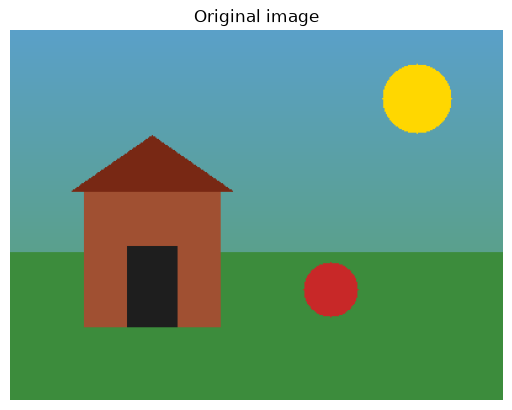

Saved copy: True


In [2]:
img = cv2.imread("../assets/test_image.png")
assert img is not None, "Image not found - check the path"
print("Loaded:", img.shape)
show(img, "Original image")
ok = cv2.imwrite("/tmp/saved_copy.png", img)
print("Saved copy:", ok)

## Image properties: shape, size, dtype and channels

`shape` is (height, width, channels). Colour images have 3 channels in **BGR** order (not RGB) - the single most common beginner mistake in OpenCV. `size` is the total number of values and `dtype` is usually `uint8` (0-255 per channel).

In [3]:
print("Height, Width, Channels:", img.shape)
print("Total values:", img.size)
print("Data type:", img.dtype)
blue, green, red = img[100, 100]
print("Pixel at (100,100) in BGR:", blue, green, red)

Height, Width, Channels: (300, 400, 3)
Total values: 360000
Data type: uint8
Pixel at (100,100) in BGR: 20 40 120


## Accessing and modifying pixels

A pixel is addressed as `img[y, x]` - row first, then column. You can read or change a single pixel, or change a whole slice at once, which is much faster than looping.

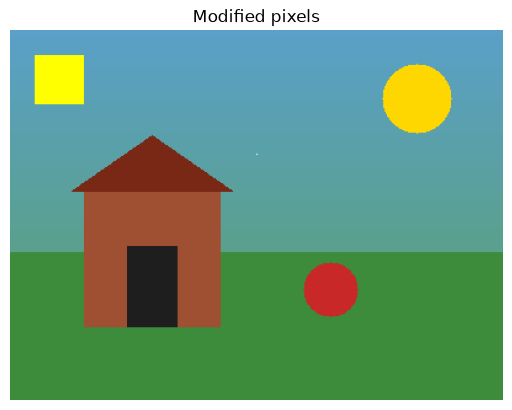

In [4]:
img2 = img.copy()
img2[20:60, 20:60] = (0, 255, 255)   # paint a yellow block (BGR)
img2[100, 200] = (255, 255, 255)     # one white pixel
show(img2, "Modified pixels")

## Splitting and merging channels

`cv2.split` separates B, G and R into single-channel images. Showing one channel alone looks grayscale - its brightness is that colour's strength at each pixel. `cv2.merge` combines channels back.

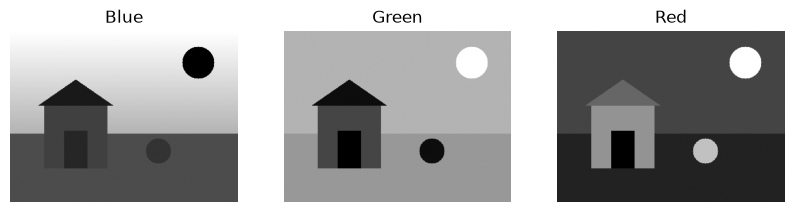

Merged shape: (300, 400, 3) | identical to original: True


In [5]:
b, g, r = cv2.split(img)
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, ch, name in zip(axes, (b, g, r), ("Blue", "Green", "Red")):
    ax.imshow(ch, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.show()
merged = cv2.merge((b, g, r))
print("Merged shape:", merged.shape, "| identical to original:", np.array_equal(merged, img))

## Region of Interest (ROI) and copying regions

An ROI is just a slice of the array. Because NumPy slices are views, modifying an ROI modifies the original unless you call `.copy()`. Copying one region onto another is the basic trick behind face swapping and object pasting.

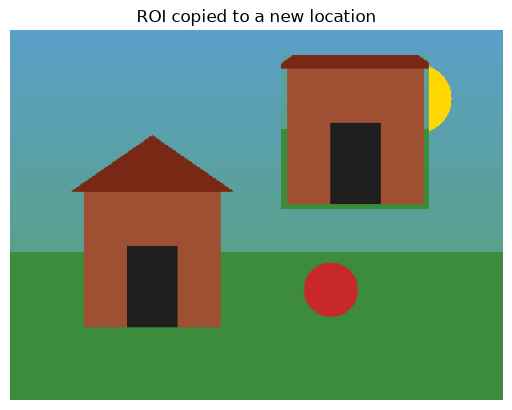

ROI shape: (125, 120, 3)


In [6]:
roi = img[120:245, 55:175].copy()   # the house area
img3 = img.copy()
img3[20:145, 220:340] = roi          # paste it somewhere else
show(img3, "ROI copied to a new location")
print("ROI shape:", roi.shape)

## Creating images from scratch and grayscale conversion

A blank canvas is a NumPy array of zeros (black) or full of 255 (white). `cv2.cvtColor` with `COLOR_BGR2GRAY` converts to a single channel, which most processing algorithms expect as input.

Colour shape: (300, 400, 3) -> Gray shape: (300, 400)


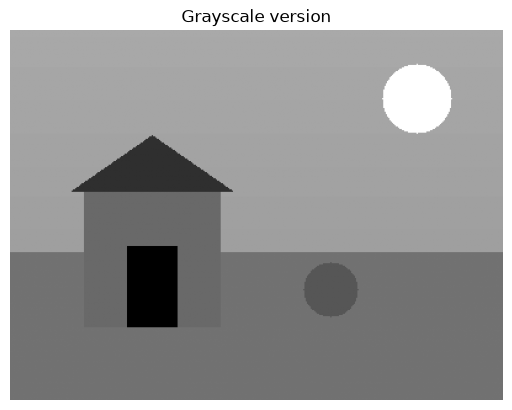

In [7]:
blank = np.zeros((200, 300, 3), np.uint8)
white = np.full((200, 300, 3), 255, np.uint8)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print("Colour shape:", img.shape, "-> Gray shape:", gray.shape)
show(gray, "Grayscale version")

## Key Points

- OpenCV reads colour images in BGR order, not RGB.
- An image is a NumPy array: shape = (height, width, channels), dtype usually uint8.
- Always check that imread did not return None before using the image.
- Pixels are addressed as img[y, x]; slices give regions of interest (ROI).
- Most algorithms work on single-channel grayscale images.

## Mini Task

1. Load `../assets/shapes.png`, print its shape and the BGR value of the centre pixel.
2. Set the top-left 50x50 block to red `(0, 0, 255)` in BGR and display the result.
3. Convert the image to grayscale and save it as `/tmp/shapes_gray.png`.